# Setup of Fetch our env variables

In [23]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

# Groq (Model Provider)
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

# Search API keys
os.environ["SERPER_API_KEY"]=os.getenv("SERP_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

print("Keys Set")

Keys Set


In [24]:
from langchain.chat_models import init_chat_model

# Use Groq as the chat model
model = init_chat_model(
    model="openai/gpt-oss-20b",
    model_provider="groq",
    temperature=0.3,
    api_key=os.getenv("GROQ_API_KEY")
)

print("LLM Initialized:", model)

response = model.invoke("Hello! Explain Generative AI in simple terms 1 line.")
print(response.content)

LLM Initialized: metadata={'lc_versions': {'langchain-core': '1.6.2', 'langchain': '1.4.0'}} profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True} client=<groq.resources.chat.completions.Completions object at 0x0000025B3690AF00> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000025B3690B200> model_name='openai/gpt-oss-20b' temperature=0.3 model_kwargs={} groq_api_key=SecretStr('**********')
Generative AI is a type of computer system that learns patterns from data and then creates new, original content—like text, images, or music—based on what it has learned.


# Search Functionality

In [5]:
from langchain_tavily import TavilySearch

tavily_search = TavilySearch(
    max_results=3,
    topic="general"
)

print("Tavily Search Initialized:", tavily_search)

Tavily Search Initialized: max_results=3 topic='general' api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None)


# Google Serper Functionality

In [9]:
from langchain_community.utilities import GoogleSerperAPIWrapper
google_search = GoogleSerperAPIWrapper()

print("Google Serper Initialized:", google_search)

Google Serper Initialized: k=10 gl='us' hl='en' type='search' result_key_for_type={'news': 'news', 'places': 'places', 'images': 'images', 'search': 'organic'} tbs=None serper_api_key='1214d00a5b7eb942089bd48d9c863ac4d7e69b08' aiosession=None


In [10]:
# test google serper
result = google_search.run("best place to visit in goa")

In [11]:
result

"See most popular tourist places to visit in Goa, top things to do, shopping and nightlife in Goa, find entry timings, fees about various attractions in Goa These rankings are informed by Tripadvisor data —we consider traveller reviews, ratings, number of page views, and user location. 1. Palolem Beach. One of the area's most picturesque beaches. 2. Baga Beach. Nice beach in North Goa with many restaurants around and plenty of parking. 3. Agonda Beach. Goa Tourism - Discover best tourist places to visit in Goa, sightseeing attractions & things to do along with itineraries, trip duration, travel guide, route map. Things to Do in Goa, India: See Tripadvisor's 767,609 traveler reviews and photos of Goa tourist attractions. Find what to do today, this weekend, or in October. We have reviews of the best places to see in Goa. Visit top-rated & must-see attractions. Discover the best places to visit in Goa, from prehistoric rock carvings to scenic backwaters, colonial forts to wildlife sanctu

In [12]:
# Test Tavily

tavily_search.invoke({"query":"best places to visit in goa"})

{'query': 'best places to visit in goa',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.youtube.com/watch?v=Q5ExzPO5BIg',
   'title': '10 of The Most Beautiful Places to Visit in Goa',
   'content': '# 10 of The Most Beautiful Places to Visit in Goa\n## Channel: Sunil Keshari (verified)\n128K subscribers\n1.4K likes\n\n### Description\n407,763 views\nPosted: 2016-11-04\n10 of The Most Beautiful Places to Visit in Goa\n\n0:00 Introduction\n0:41 Dona Paula Jetty (GOA)\n1:20 AGUADA FORT (GOA)\n2:25 Palolem Beach (GOA)\n4:08 Shri Mangeshi Temple (GOA)\n6:02 Panjim Church (GOA)\n6:31 Cansaulim Monte (GOA)\n8:01 Colva Beach (GOA)\n9:00 Dudhsagar Falls (GOA)\n10:00 10.Basilica of Bom Jesus (GOA) [...] ### Chapters\n[0:00] Introduction\n[0:41] Dona Paula Jetty (GOA)\n[1:20] AGUADA FORT (GOA)\n[2:25] Palolem Beach (GOA)\n[4:08] Shri Mangeshi Temple (GOA)\n[6:02] Panjim Church (GOA)\n[6:31] Cansaulim Monte (GOA)\n[8:01] Colva Beach (GOA)\n[9:00] D

In [13]:
def tavily_search_tool(query: str) -> str:
    """ 
    Search the web using Tavily for Travel Info, Tips, Attractions etc.
    """
    # Call the existing Tavily Search Tool Underneath
    return tavily_search.invoke({"query": query})

In [14]:
def google_search_tool(query: str) -> str:
    """ 
    Search the web using Google Serper API for upto date travel info.
    """
    return google_search.run(query)

In [15]:
google_search_tool("Plan a tour to india in 3 lines")

"Here is a day-by-day itinerary of how to spend three weeks in India. It's based on our north (New Delhi) to south (Kochi) trip with G ... 00:00 Intro ; 01:32 \u200b Tips for your Trip ; 03:20 Day 1 - Flying to India ; 03:59\u200b Day 2 - Exploring Delhi \u200b ; 10:38 Day 3 - Delhi Food Tour ... Remarkable 21-day tour spanning 13 cities from Mumbai to Delhi. Features 6 wildlife safaris, visits to UNESCO sites like Sanchi Stupas, and medieval cities. India Golden Triangle Tour ... Many first-time visitors do a Golden Triangle tour, which visits the three cities of Delhi, Jaipur and Agra, to see the Taj Mahal. This 3 Days Golden Triangle Tour of India cover India's most popular tourist destinations. Delhi, Agra and Jaipur are one of the major ... 1. India's Golden Triangle & tigers · 2. Classic Rajasthan tour: forts, palaces & rural villages · 3. India's wildlife treasures · 4. Classic Kerala tour: culture, ... Explore India itineraries from 7–14 days. Get inspired and customize your tr

In [2]:
from langchain.agents import create_agent
#from langgraph.runtime import ExecutionInfo

system_prompt = """
You are a travel planner assistant. User asks travel queries like 'Plan my trip to X','what to do in Y Hotel' ,etc.
Always use the available web search tools (TavilySearch, GoogleSerperSearch) to get the latest real-world travel information.
Provide a helpful and clear itinerary/answer. 
"""

Travel Planner Agent Ready


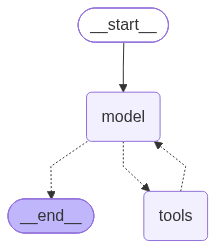

In [16]:
agent = create_agent(
    model=model,
    tools=[tavily_search_tool, google_search_tool],
    system_prompt=system_prompt.strip()
)

print("Travel Planner Agent Ready")
agent

In [17]:
# Test the Agent
response = agent.invoke({
      "messages":[
          {"role": "user",
           "content":"Give me 3 day plan for South goa visit"}
      ]
    
    })

In [20]:
print(response["messages"][-1].content)

# 🏖️ 3-Day South Goa Itinerary

South Goa is the laid-back, scenic side of Goa — think golden beaches, quiet backwaters, Portuguese heritage, and lush greenery. Here's a well-balanced 3-day plan mixing beaches, culture, and nature.

---

## 📍 Day 1: Beaches & Coastal Charm (Palolem – Agonda – Colva)

**Morning**
- Start at **Palolem Beach** — the most picturesque beach in Goa, with its crescent-shaped bay and calm waters. Great for swimming, kayaking, and snorkeling.
- Take a **boat ride** for dolphin spotting or explore the small islands.

**Afternoon**
- Head to **Agonda Beach** — quieter and perfect for unwinding. Try a beachside café or a yoga session.
- Stroll to nearby **Butterfly Beach** (a short trek or boat ride) for a hidden, pristine stretch.

**Evening**
- Drive to **Colva Beach** for sunset.
- Dinner at a beach shack in Colva or Benaulim — try fresh seafood (fish curry, prawns) or veg Goan thali.

> 🏨 Stay: Palolem/Agonda area for beachfront vibes, or Colva/Benaulim for mo

In [19]:
response["messages"]

[HumanMessage(content='Give me 3 day plan for South goa visit', additional_kwargs={}, response_metadata={}, id='31c9bd8f-48b1-4651-b35e-64d82bd3f35c'),
 AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'ymbg83t8z', 'function': {'arguments': '{"query":"best places to visit in South Goa 3 day itinerary"}', 'name': 'tavily_search_tool'}, 'type': 'function'}, {'id': 'aaw2v889v', 'function': {'arguments': '{"query":"South Goa 3 day trip plan beaches temples"}', 'name': 'google_search_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 73, 'prompt_tokens': 425, 'total_tokens': 498, 'completion_time': 0.220949234, 'completion_tokens_details': None, 'prompt_time': 0.029818364, 'prompt_tokens_details': None, 'queue_time': 0.050993096, 'total_time': 0.250767598}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_ru